In [13]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns 

from sklearn.cluster import KMeans,AgglomerativeClustering , DBSCAN
from sklearn.decomposition import PCA 
from sklearn.preprocessing import StandardScaler

In [14]:
"""
Part 1: The Clean-Up (Preprocessing)
"""

data = pd.read_csv('Mall_Customers.csv')
print(data.head())
print(data.shape) # 200x5
print(data.info()) # only 1 non-numeric column (Gender)
print(data.isna().sum()) # no missing values

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
(200, 5)
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB
None
CustomerID                0
Gender                    0
Age     

In [15]:
data.drop(columns=['CustomerID', "Gender", "Age"], inplace=True) # dropping useless features

scaler = StandardScaler()
data_scaled = scaler.fit_transform(data) # scaling the data to have mean=0 and std=1

C:\Users\moham\AppData\Local\Temp\ipykernel_8688\3578339640.py:1: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(data_scaled[:, 0], data_scaled[:, 1], c='blue', cmap='viridis', s=30, edgecolors='blue')


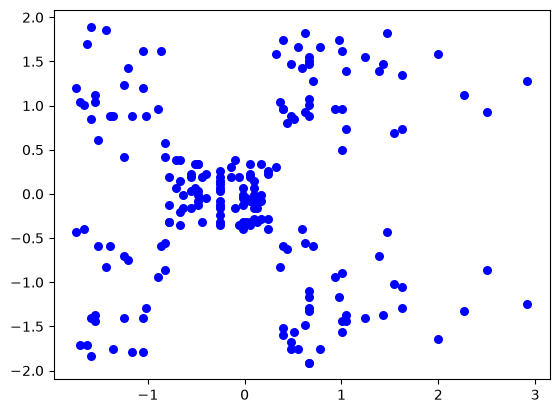

In [16]:
plt.scatter(data_scaled[:, 0], data_scaled[:, 1], c='blue', cmap='viridis', s=30, edgecolors='blue')
# Not clustered yet, just visualizing the data after scaling

K=2, WCSS=274.09
K=3, WCSS=157.70
K=4, WCSS=108.92
K=5, WCSS=65.57
K=6, WCSS=57.38
K=7, WCSS=47.34
K=8, WCSS=42.43
K=9, WCSS=32.81
K=10, WCSS=29.62


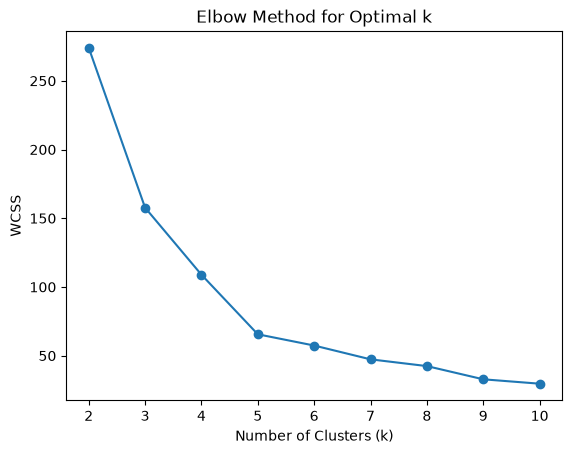

In [17]:
"""
Part 2: The Hunt for K (K-Means)
"""

k_range = range(2, 11)
inertia = []
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=0)
    kmeans.fit(data_scaled)
    wcss = kmeans.inertia_
    inertia.append(wcss)
    print(f"K={k}, WCSS={wcss:.2f}")
    
plt.plot(k_range, inertia, marker='o')
plt.title('Elbow Method for Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS')
plt.show()
# therfore elbow point is at k=5, so we will use k=5 for KMeans clustering

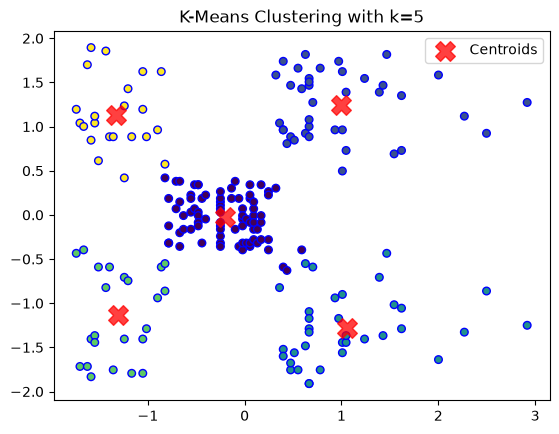

In [18]:
"""Part 3: The Reveal (Visualization & Interpretation)"""

k_means_final = KMeans(n_clusters=5, random_state=0)
k_means_final.fit(data_scaled)
plt.scatter(data_scaled[:, 0], data_scaled[:, 1], c=k_means_final.labels_, cmap='viridis', s=30, edgecolors='blue')
plt.scatter(k_means_final.cluster_centers_[:, 0], k_means_final.cluster_centers_[:, 1], c='red', s=200, alpha=0.75, marker='X', label='Centroids')
# marking the centroids of the clusters with a red 'X' marker
plt.title('K-Means Clustering with k=5')
plt.legend()
plt.show()


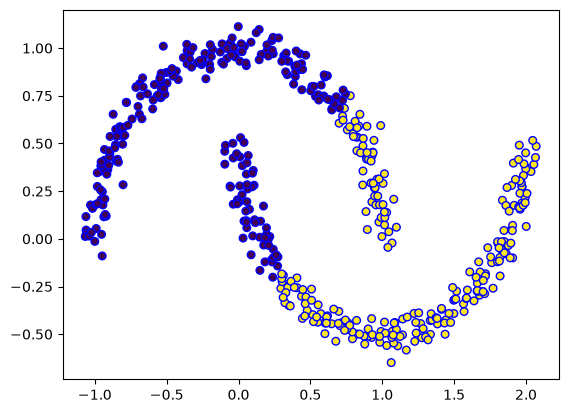

In [19]:
"""
Part 4: The "Glitch" (DBSCAN vs. K-Means)
"""
# Step 1: Generate Synthetic Data

from sklearn.datasets import make_moons

moons_data, moons_labels = make_moons(n_samples=500, noise=0.05, random_state=0)

# Step 2: Fail Test K-Means on Moon Data

k_means_moons = KMeans(n_clusters=2, random_state=0)
k_means_moons.fit(moons_data)

plt.scatter(moons_data[:, 0], moons_data[:, 1], c=k_means_moons.labels_, cmap='viridis', s=30, edgecolors='blue') # Failed as K-Means cannot capture the non-linear structure of the moon-shaped data (the clusters are not well-separated)

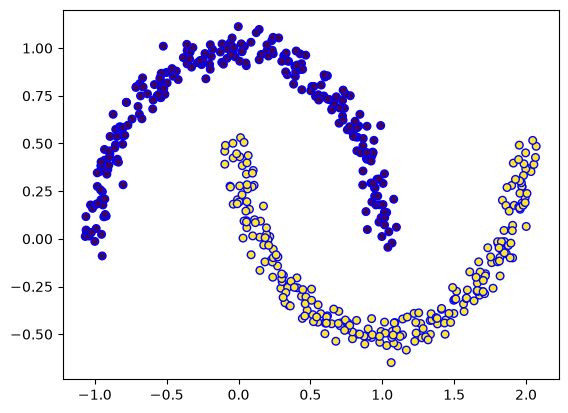

In [20]:
# Step 3: Success Test DBSCAN on Moon Data

from sklearn.cluster import DBSCAN

dbscan_moons = DBSCAN(eps=0.2, min_samples=5)
dbscan_moons.fit_predict(moons_data)
plt.scatter(moons_data[:, 0], moons_data[:, 1], c=dbscan_moons.labels_, cmap='viridis', s=30, edgecolors='blue') # DBSCAN successfully captures the non-linear structure of the moon-shaped data (the clusters are well-separated)

In [21]:
"""Conclusion
Summarize insights and compare K-Means vs. DBSCAN performance on different data shapes."""

""" K-Means: works well for spherical/round clusters, but fails for non-linear shapes like moons. Also need to manually specify the number of clusters (k). It is very fast and efficient for large datasets, but sensitive to outliers and noise."""

"""DBSCAN: works well for non-linear shapes and can automatically determine the number of clusters based on density. It is robust to outliers and noise, but can be slower for large datasetss (O(n^2))."""

'DBSCAN: works well for non-linear shapes and can automatically determine the number of clusters based on density. It is robust to outliers and noise, but can be slower for large datasetss (O(n^2)).'